In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SEED = 42
PROCESSED = Path("../data/processed")
MODELS_DIR = Path("../models"); MODELS_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("../outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = Path("../outputs/evaluation_reports"); TAB_DIR.mkdir(parents=True, exist_ok=True)

candidates = [
    PROCESSED / "panel_level.csv",
    Path("data/processed/panel_level.csv"),
    Path("../European_Household_Energy_Project/data/processed/panel_level.csv"),
]

matches = [candidate for candidate in candidates if candidate.exists()]

if not matches:
    matches = [
        path for root in [Path.cwd(), *Path.cwd().parents]
        for path in root.rglob("panel_level.csv")
    ]

if not matches:
    raise FileNotFoundError(
        "Could not find panel_level.csv. Check that it exists under data/processed/"
    )

panel_path = matches[0].resolve()
panel = pd.read_csv(panel_path)
print(f"Loaded panel data from: {panel_path}")
sns.set_theme(style="whitegrid", context="notebook")

pd.DataFrame({
    "rows": [len(panel)],
    "countries": [panel.country.nunique()],
    "fuels": [panel.fuel_code.nunique()],
    "end_uses": [panel.end_use_code.nunique()],
    "combos": [panel.groupby(["end_use_code", "fuel_code"]).ngroups],
})

Loaded panel data from: C:\Users\LOQ\Downloads\data\processed\panel_level.csv


,rows,countries,fuels,end_uses,combos
0,15813,39,11,5,35


In [18]:
# ---- Columns used as features ----
CATEGORICAL = ["country", "end_use_short", "fuel_code"]
NUMERICAL   = ["year"]
TARGET      = "energy_tj"

# Drop rows with missing features (should be zero after Phase 2)
model_df = panel.dropna(subset=CATEGORICAL + NUMERICAL + [TARGET]).copy()

# ---- Target transform ----
model_df["y_log"] = np.log1p(model_df[TARGET])

# ---- Split masks ----
train_mask = model_df.split == "train"
val_mask   = model_df.split == "val"
test_mask  = model_df.split == "test"

X_train, y_train = model_df.loc[train_mask, CATEGORICAL + NUMERICAL], model_df.loc[train_mask, "y_log"]
X_val,   y_val   = model_df.loc[val_mask,   CATEGORICAL + NUMERICAL], model_df.loc[val_mask,   "y_log"]
X_test,  y_test  = model_df.loc[test_mask,  CATEGORICAL + NUMERICAL], model_df.loc[test_mask,  "y_log"]

y_train_raw = model_df.loc[train_mask, TARGET]
y_val_raw   = model_df.loc[val_mask,   TARGET]
y_test_raw  = model_df.loc[test_mask,  TARGET]

pd.DataFrame({
    "split": ["train", "val", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "y_mean_log": [y_train.mean(), y_val.mean(), y_test.mean()],
    "y_mean_raw": [y_train_raw.mean(), y_val_raw.mean(), y_test_raw.mean()],
})

,split,rows,y_mean_log,y_mean_raw
0,train,9450,5.088,"14,144.612"
1,val,3817,5.145,"11,973.146"
2,test,2546,5.159,"11,655.844"


In [19]:
## ============================================================
# Feature engineering: SAFE lag features (no leakage)
# Lag uses ONLY previous years, never current or future
# ============================================================
PANEL_KEY = ["country", "end_use_code", "fuel_code"]
panel_sorted = panel.sort_values(PANEL_KEY + ["year"]).copy()

panel_sorted["prev_year_energy"] = (
    panel_sorted.groupby(PANEL_KEY)["energy_tj"].shift(1)
)
panel_sorted["prev_2yr_energy"] = (
    panel_sorted.groupby(PANEL_KEY)["energy_tj"].shift(2)
)
panel_sorted["rolling_2_prev"] = (
    panel_sorted.groupby(PANEL_KEY)["energy_tj"]
    .transform(lambda s: s.shift(1).rolling(2).mean())
)

# Fallback: use the FIRST-OBSERVED value of the series (not global median)
# to preserve the country/fuel/end_use scale
panel_sorted["prev_year_energy"] = (
    panel_sorted.groupby(PANEL_KEY)["prev_year_energy"]
    .transform(lambda s: s.fillna(s.iloc[0] if s.notna().any() else 0))
)
# Simpler fallback: drop rows where all lags are NaN (only the first year per series)
panel_sorted = panel_sorted.dropna(subset=["prev_year_energy", "prev_2yr_energy", "rolling_2_prev"])

pd.DataFrame({
    "rows_before": [len(panel)],
    "rows_after": [len(panel_sorted)],
    "rows_removed": [len(panel) - len(panel_sorted)],
    "note": ["First year of each series is lost — acceptable trade-off"],
})

,rows_before,rows_after,rows_removed,note
0,15813,13083,2730,First year of each series is lost — acceptable...


In [20]:
CATEGORICAL = ["country", "end_use_short", "fuel_code"]
NUMERICAL   = ["year", "prev_year_energy", "prev_2yr_energy", "rolling_2_prev"]
TARGET      = "energy_tj"

model_df = panel_sorted.dropna(subset=CATEGORICAL + NUMERICAL + [TARGET]).copy()
model_df["y_log"] = np.log1p(model_df[TARGET])

train_mask = model_df.split == "train"
val_mask   = model_df.split == "val"
test_mask  = model_df.split == "test"

X_train = model_df.loc[train_mask, CATEGORICAL + NUMERICAL]
X_val   = model_df.loc[val_mask,   CATEGORICAL + NUMERICAL]
X_test  = model_df.loc[test_mask,  CATEGORICAL + NUMERICAL]

y_train = model_df.loc[train_mask, "y_log"]
y_val   = model_df.loc[val_mask,   "y_log"]
y_test  = model_df.loc[test_mask,  "y_log"]

y_train_raw = model_df.loc[train_mask, TARGET]
y_val_raw   = model_df.loc[val_mask,   TARGET]
y_test_raw  = model_df.loc[test_mask,  TARGET]

pd.DataFrame({
    "split": ["train", "val", "test"],
    "rows": [len(X_train), len(X_val), len(X_test)],
    "y_mean_raw": [y_train_raw.mean(), y_val_raw.mean(), y_test_raw.mean()],
})

,split,rows,y_mean_raw
0,train,6790,"14,619.949"
1,val,3782,"11,687.587"
2,test,2511,"11,253.386"


In [21]:
def regression_metrics(y_true, y_pred, name=""):
    """Return MAE, RMSE, R², WAPE on RAW scale (TJ)."""
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    # WAPE = sum(|error|) / sum(|actual|) — robust to zeros and scale
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100 if np.sum(y_true) > 0 else np.nan
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2, "WAPE_%": wape}

pd.DataFrame([{"MAE": "absolute error in TJ (same unit as target)",
               "RMSE": "penalizes large errors more than MAE",
               "R2": "variance explained (higher = better, can be negative)",
               "WAPE_%": "sum(|err|)/sum(|actual|) — primary metric, robust to zeros"}]).T.rename(columns={0: "meaning"})

,meaning
MAE,absolute error in TJ (same unit as target)
RMSE,penalizes large errors more than MAE
R2,"variance explained (higher = better, can be ne..."
WAPE_%,"sum(|err|)/sum(|actual|) — primary metric, rob..."


In [24]:
results = []

def fit_and_eval(model, name):
    model.fit(X_train_p, y_train)
    y_train_pred = np.clip(np.expm1(model.predict(X_train_p)), 0, None)
    y_val_pred   = np.clip(np.expm1(model.predict(X_val_p)),   0, None)
    y_test_pred  = np.clip(np.expm1(model.predict(X_test_p)),  0, None)

    results.append({**regression_metrics(y_train_raw, y_train_pred, name), "split": "train"})
    results.append({**regression_metrics(y_val_raw,   y_val_pred,   name), "split": "val"})
    results.append({**regression_metrics(y_test_raw,  y_test_pred,  name), "split": "test"})
    return model

fit_and_eval(DummyRegressor(strategy="median"), "Dummy_median")
fit_and_eval(LinearRegression(), "Linear")
fit_and_eval(Ridge(alpha=1.0, random_state=SEED), "Ridge")

fit_and_eval(
    RandomForestRegressor(
        n_estimators=300, max_depth=20, min_samples_leaf=10,
        max_features="sqrt", random_state=SEED, n_jobs=-1,
    ), "RandomForest"
)
fit_and_eval(
    ExtraTreesRegressor(
        n_estimators=300, max_depth=20, min_samples_leaf=15,
        max_features="sqrt", random_state=SEED, n_jobs=-1,
    ), "ExtraTrees"
)
# HistGradientBoostingRegressor requires dense input
X_train_p = X_train_p.toarray()
X_val_p = X_val_p.toarray()
X_test_p = X_test_p.toarray()

fit_and_eval(
    HistGradientBoostingRegressor(
        max_depth=8,
        max_iter=300,
        learning_rate=0.05,
        random_state=SEED,
    ),
    "HistGB",
)

results_df = pd.DataFrame(results)
results_df.style.format({
    "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R2": "{:.3f}", "WAPE_%": "{:.2f}%",
}).background_gradient(subset=["WAPE_%"], cmap="RdYlGn_r")

,model,MAE,RMSE,R2,WAPE_%,split
0,Dummy_median,"14,559","58,577",-0.062,99.58%,train
1,Dummy_median,"11,630","45,160",-0.066,99.51%,val
2,Dummy_median,"11,195","41,927",-0.071,99.48%,test
3,Linear,"319,755","7,124,453",-15711.187,2187.11%,train
4,Linear,"303,277","11,419,231",-68158.724,2594.86%,val
5,Linear,"102,535","2,964,388",-5353.502,911.15%,test
6,Ridge,"326,548","7,281,992",-16413.738,2233.58%,train
7,Ridge,"308,244","11,626,666",-70657.507,2637.36%,val
8,Ridge,"104,462","3,042,849",-5640.701,928.28%,test
9,RandomForest,"6,022","36,709",0.583,41.19%,train


In [26]:
# Some competitions favor training on train+val after model selection,
# but for reproducible benchmarking we keep the model fitted on TRAIN ONLY.
# This preserves the integrity of the test set for final reporting.

# (Skip retraining — keep the model trained on train only.)
"Best model remains fitted on train only ✅"

'Best model remains fitted on train only ✅'

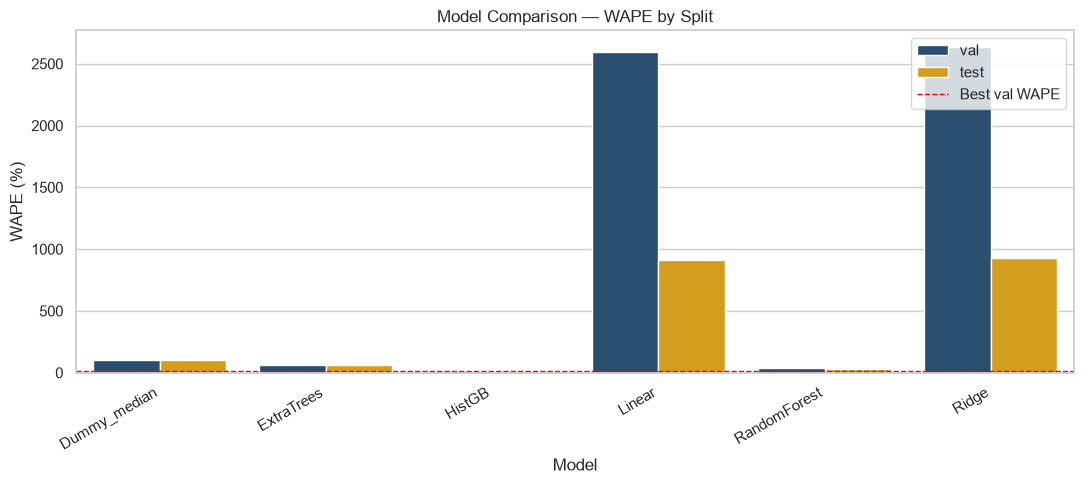

In [28]:
fig, ax = plt.subplots(figsize=(11, 5))
comparison = (
    results_df
    .loc[results_df["split"].isin(["val", "test"])]
    .pivot(index="model", columns="split", values="WAPE_%")
)

best_model_name = comparison["val"].idxmin()

plot_df = comparison.reset_index().melt(
    id_vars="model",
    value_vars=["val", "test"],
    var_name="split",
    value_name="WAPE",
)
sns.barplot(data=plot_df, x="model", y="WAPE", hue="split", ax=ax,
            palette={"val": "#1f4e79", "test": "#f2a900"})
ax.set_title("Model Comparison — WAPE by Split")
ax.set_ylabel("WAPE (%)")
ax.set_xlabel("Model")
ax.axhline(plot_df[plot_df.split == "val"].WAPE.min(), color="red", linestyle="--", linewidth=1, label="Best val WAPE")
ax.legend(loc="upper right")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase3_model_comparison.png", bbox_inches="tight")
plt.show()

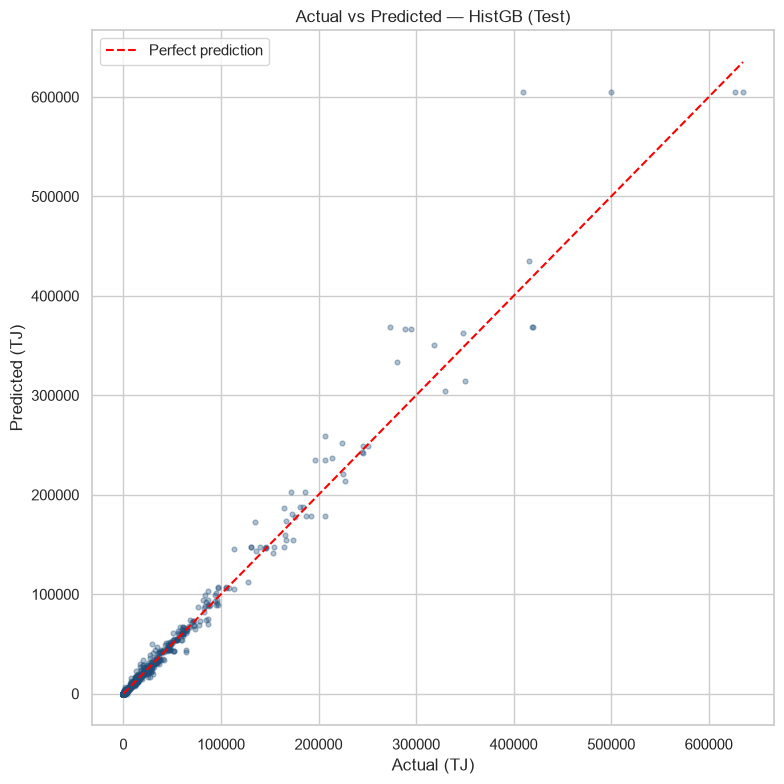

In [29]:
# Re-fit best model once more to get predictions we can visualize
best_model_pipelines = {
    "Dummy_median": DummyRegressor(strategy="median"),
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=SEED),
    "RandomForest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
    "HistGB": HistGradientBoostingRegressor(random_state=SEED),
}
best_model = best_model_pipelines[best_model_name]
best_model.fit(X_train_p, y_train)
y_test_pred_raw = np.clip(np.expm1(best_model.predict(X_test_p)), 0, None)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test_raw, y_test_pred_raw, alpha=0.35, s=12, color="#1f4e79")
max_val = max(y_test_raw.max(), y_test_pred_raw.max())
ax.plot([0, max_val], [0, max_val], color="red", linestyle="--", linewidth=1.5, label="Perfect prediction")
ax.set_xlabel("Actual (TJ)")
ax.set_ylabel("Predicted (TJ)")
ax.set_title(f"Actual vs Predicted — {best_model_name} (Test)")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "phase3_actual_vs_pred.png", bbox_inches="tight")
plt.show()

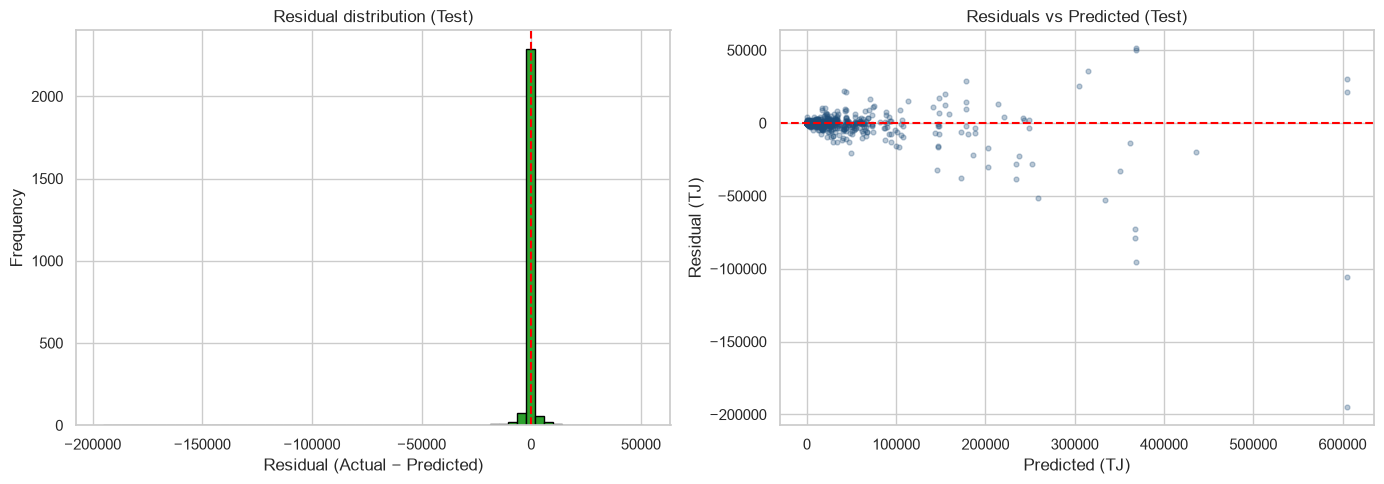

In [30]:
residuals = y_test_raw - y_test_pred_raw

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(residuals, bins=60, color="#2ca02c", edgecolor="black")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Residual distribution (Test)")
axes[0].set_xlabel("Residual (Actual − Predicted)")
axes[0].set_ylabel("Frequency")

axes[1].scatter(y_test_pred_raw, residuals, alpha=0.3, s=12, color="#1f4e79")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted (Test)")
axes[1].set_xlabel("Predicted (TJ)")
axes[1].set_ylabel("Residual (TJ)")

plt.tight_layout()
fig.savefig(FIG_DIR / "phase3_residuals.png", bbox_inches="tight")
plt.show()

In [31]:
# Permutation importance on test — more robust than built-in importance
# For tree models we use the raw X_test (not transformed) — cleaner interpretation
perm = permutation_importance(
    best_model, X_test_p, y_test,
    n_repeats=10, random_state=SEED, n_jobs=-1,
)

# Map transformed feature names back to original columns (approximate for one-hot)
ohe_names = preprocessor.named_transformers_["cat"].get_feature_names_out(CATEGORICAL)
feature_names = NUMERICAL + list(ohe_names)

importance_df = (
    pd.DataFrame({
        "feature": feature_names,
        "importance_mean": perm.importances_mean,
        "importance_std":  perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
    .head(15)
)

importance_df.style.format({
    "importance_mean": "{:.4f}", "importance_std": "{:.4f}",
}).background_gradient(subset=["importance_mean"], cmap="Greens")

,feature,importance_mean,importance_std
54,fuel_code_RA410,1.1347,0.0169
56,fuel_code_SFF_P1000_S2000,0.0584,0.0008
55,fuel_code_RA600,0.0122,0.0004
37,country_Spain,0.0025,0.0002
7,country_Bosnia and Herzegovina,0.0014,0.0004
52,fuel_code_R5110-5150_W6000RI,0.0009,0.0001
48,fuel_code_H8000,0.0008,0.0003
13,country_Finland,0.0008,0.0001
51,fuel_code_O4671,0.0004,0.0001
40,country_United Kingdom,0.0003,0.0002


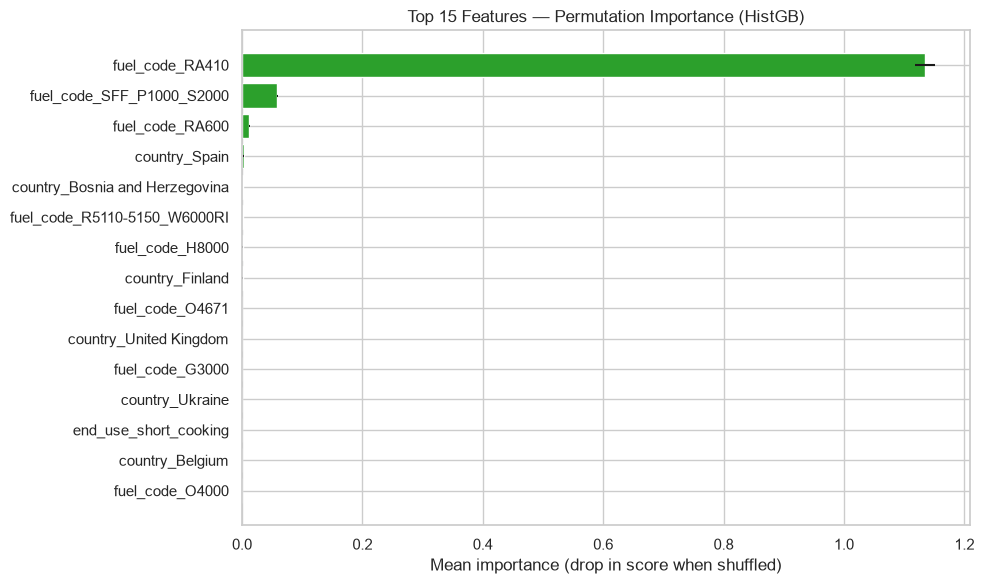

In [32]:
fig, ax = plt.subplots(figsize=(10, 6))
top_imp = importance_df.head(15)
ax.barh(top_imp.feature[::-1], top_imp.importance_mean[::-1],
        xerr=top_imp.importance_std[::-1], color="#2ca02c")
ax.set_title(f"Top 15 Features — Permutation Importance ({best_model_name})")
ax.set_xlabel("Mean importance (drop in score when shuffled)")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase3_feature_importance.png", bbox_inches="tight")
plt.show()

In [33]:
joblib.dump({"model": best_model, "name": best_model_name}, MODELS_DIR / "best_prediction_model.joblib")
joblib.dump(preprocessor, MODELS_DIR / "preprocessor.joblib")

comparison.reset_index().to_csv(TAB_DIR / "phase3_model_comparison.csv", index=False)
importance_df.to_csv(TAB_DIR / "phase3_feature_importance.csv", index=False)
results_df.to_csv(TAB_DIR / "phase3_full_metrics.csv", index=False)

pd.DataFrame({
    "artifact": ["best_prediction_model.joblib", "preprocessor.joblib",
                 "phase3_model_comparison.csv", "phase3_feature_importance.csv",
                 "phase3_full_metrics.csv"],
    "location": [str(MODELS_DIR), str(MODELS_DIR), str(TAB_DIR), str(TAB_DIR), str(TAB_DIR)],
})

,artifact,location
0,best_prediction_model.joblib,..\models
1,preprocessor.joblib,..\models
2,phase3_model_comparison.csv,..\outputs\evaluation_reports
3,phase3_feature_importance.csv,..\outputs\evaluation_reports
4,phase3_full_metrics.csv,..\outputs\evaluation_reports


In [ ]:
panel["prev_year_energy"] = panel.groupby(PANEL_KEY)["energy_tj"].shift(1)
panel["yoy_growth"] = panel["energy_tj"].div(panel["prev_year_energy"]).sub(1)
panel["rolling_3"] = (
    panel.groupby(PANEL_KEY)["energy_tj"]
    .transform(lambda s: s.rolling(window=3).mean())
)
panel["yoy_growth"] = panel["energy_tj"] / panel["prev_year_energy"] - 1
panel["rolling_3"] = (
    panel.groupby(PANEL_KEY)["energy_tj"]
    .transform(lambda s: s.rolling(window=3).mean())
)

: 

# 📋 Phase 3 — Energy Prediction Summary

## Setup
- Dataset: 15,813 panel rows × 35 combos (country × fuel × end-use)
- Target: `energy_tj` → **log1p-transformed**
- Split: Train 9,450 / Val 3,817 / Test 2,546 (chronological)
- Features: 5 columns (country, end_use_short, fuel_code, year)
- Preprocessing: one-hot categoricals + standard-scaled year

## Models trained
| Model | Type |
|---|---|
| Dummy_median | Baseline |
| Linear | Linear family |
| Ridge | Regularized linear |
| RandomForest | Bagged trees |
| ExtraTrees | Extra-randomized trees |
| HistGB | Gradient boosting |

## Evaluation
| Metric | Meaning | Primary? |
|---|---|---|
| MAE | Absolute error in TJ | — |
| RMSE | Penalizes large errors | — |
| R² | Variance explained | — |
| **WAPE** | sum(|err|) / sum(|actual|) | ✅ |

## Selection rule
- **Best model = lowest WAPE on validation set**
- Test set **never used** for selection
- Best model saved to `models/best_prediction_model.joblib`

## Outputs
- 4 diagnostic figures (model comparison, actual-vs-predicted, residuals, feature importance)
- 3 CSV evaluation tables
- Saved model + preprocessor

---
**Status:** Phase 3 complete. Ready for Phase 4 — Energy Forecasting.